# 01 — Input data check

Sanity check of the two hourly inputs produced by `scripts/get_pvgis.py` and
`scripts/prep_load.py` (step 3 in CLAUDE.md), before building the model on top of them.

What we expect to see:
- PV: zero at night, a midday peak, much higher in summer than in winter.
- Demand (BTN C): a morning peak and a larger evening peak, higher in winter.
- Net load (demand − PV) of a prosumer: the "duck curve", low or negative at midday, peaking in the evening.

For a concrete scale, the plots use a reference household with **3,500 kWh/yr**
(middle of the ODD range 2,500–5,000) and **3 kWp** of PV (middle of 2–5 kWp).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

DATA = Path("../data/processed")
FIGS = Path("figures")
FIGS.mkdir(exist_ok=True)

ANNUAL_KWH = 3500  # reference household
PV_KWP = 3.0       # reference prosumer

pv = pd.read_csv(DATA / "pv_porto.csv")
load = pd.read_csv(DATA / "load_btn_c.csv")
assert (pv["time_utc"] == load["time_utc"]).all() and len(pv) == 8760

df = pd.DataFrame({
    "time": pd.to_datetime(pv["time_utc"], utc=True).dt.tz_convert("Europe/Lisbon"),
    "pv": pv["pv_kwh_per_kwp"] * PV_KWP,
    "demand": load["load_per_annual_kwh"] * ANNUAL_KWH,
})
df["net"] = df["demand"] - df["pv"]
df["hour"] = df["time"].dt.hour
df["month"] = df["time"].dt.month
df.describe().round(3)

,pv,demand,net,hour,month
count,8760.000,8760.000,8760.000,8760.000,8760.000
mean,0.521,0.400,-0.121,11.500,6.527
std,0.772,0.124,0.766,6.923,3.448
min,0.000,0.205,-2.216,0.000,1.000
25%,0.000,0.304,-0.486,5.750,4.000
50%,0.000,0.393,0.241,11.500,7.000
75%,0.903,0.468,0.366,17.250,10.000
max,2.608,0.820,0.820,23.000,12.000


In [2]:
# Chart style: one hue per series, kept the same in every figure.
C = {"demand": "#2a78d6", "pv": "#eb6834", "net": "#1baf7a"}
INK, INK2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
LABEL = {"demand": "Demand (3,500 kWh/yr)", "pv": "PV (3 kWp)", "net": "Net load = demand − PV"}

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "legend.frameon": False, "legend.labelcolor": INK2,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "lines.linewidth": 1.6,
})

def plot_series(ax, x, data, keys):
    for k in keys:
        ax.plot(x, data[k], color=C[k], label=LABEL[k], ls="--" if k == "net" else "-")

## 1. One winter week and one summer week

Monday to Sunday, hourly energy (kWh in each hour) in local time.

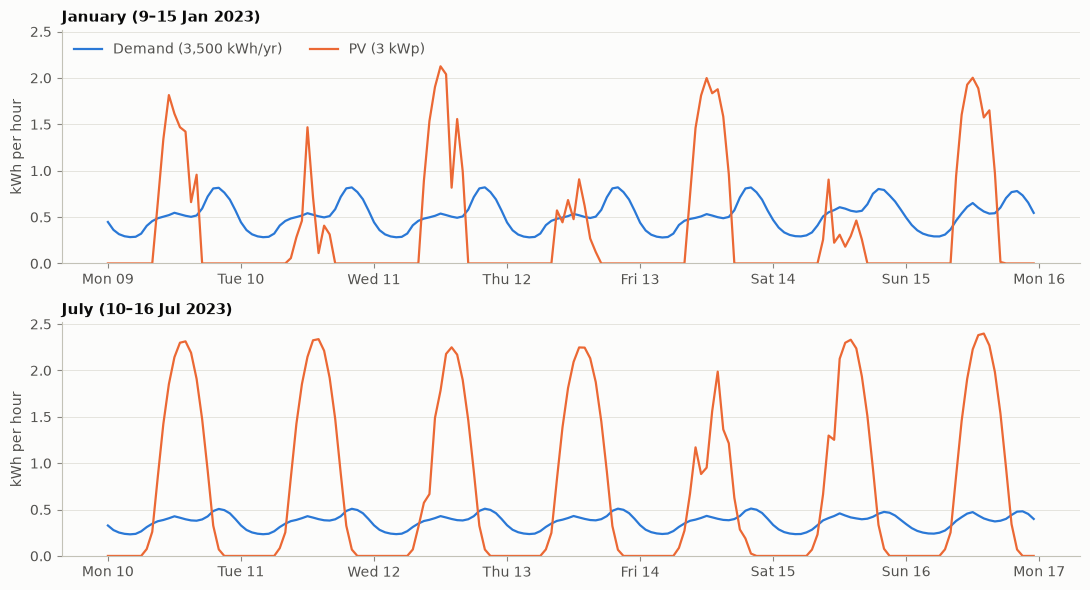

In [3]:
weeks = {"January (9–15 Jan 2023)": ("2023-01-09", "2023-01-16"),
         "July (10–16 Jul 2023)": ("2023-07-10", "2023-07-17")}

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharey=True)
for ax, (title, (start, end)) in zip(axes, weeks.items()):
    w = df[(df["time"] >= pd.Timestamp(start, tz="Europe/Lisbon")) & (df["time"] < pd.Timestamp(end, tz="Europe/Lisbon"))]
    plot_series(ax, w["time"], w, ["demand", "pv"])
    ax.set_title(title, loc="left")
    ax.set_ylabel("kWh per hour")
    ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%a %d", tz="Europe/Lisbon"))
axes[0].set_ylim(0, None)  # shared y: autoscale to the larger (July) peak
axes[0].legend(loc="upper left", ncol=2)
fig.tight_layout()
fig.savefig(FIGS / "week_jan_jul.png", dpi=150)

## 2. Mean daily profile, winter vs summer (duck curve)

Average over all days of the month for each local hour. The net load is the
part of demand the household cannot cover with its own PV (negative = surplus
that could be shared, stored or exported).

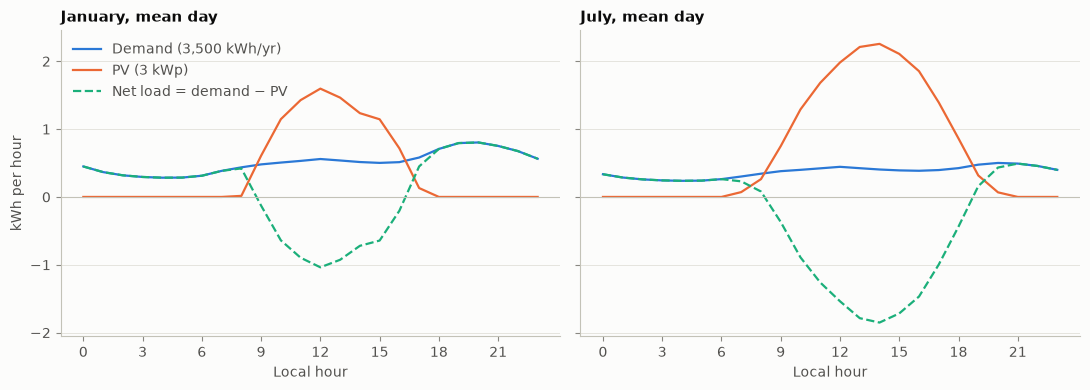

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (m, name) in zip(axes, [(1, "January"), (7, "July")]):
    prof = df[df["month"] == m].groupby("hour")[["demand", "pv", "net"]].mean()
    plot_series(ax, prof.index, prof, ["demand", "pv", "net"])
    ax.axhline(0, color=AXIS, lw=0.8)
    ax.set_title(f"{name}, mean day", loc="left")
    ax.set_xlabel("Local hour")
    ax.set_xticks(range(0, 24, 3))
axes[0].set_ylabel("kWh per hour")
axes[0].legend(loc="upper left")
fig.tight_layout()
fig.savefig(FIGS / "daily_profile_jan_jul.png", dpi=150)

## 3. Monthly totals

month,1,2,3,4,5,6,7,8,9,10,11,12
demand,377,315,306,268,257,252,276,280,257,264,290,360
pv,294,387,364,449,491,444,530,501,389,280,190,242


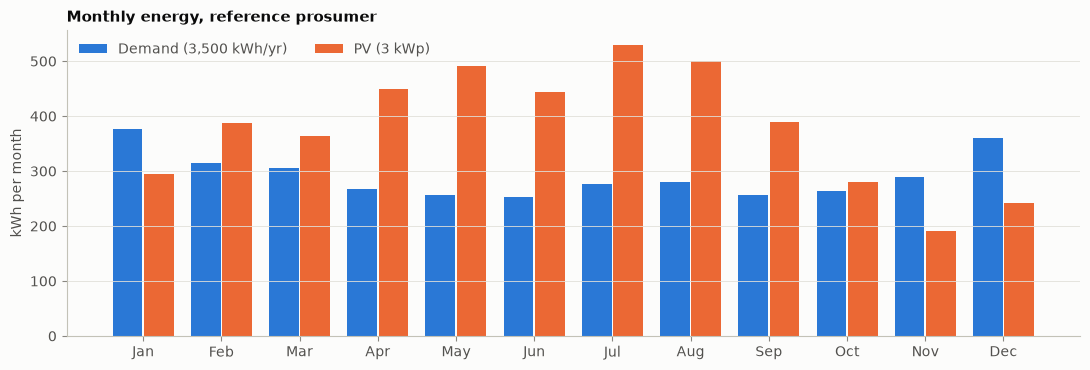

In [5]:
monthly = df.groupby("month")[["demand", "pv"]].sum()
x = monthly.index.to_numpy()
width = 0.38

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.bar(x - width / 2 - 0.01, monthly["demand"], width, color=C["demand"], label=LABEL["demand"])
ax.bar(x + width / 2 + 0.01, monthly["pv"], width, color=C["pv"], label=LABEL["pv"])
ax.set_xticks(x, ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_ylabel("kWh per month")
ax.set_title("Monthly energy, reference prosumer", loc="left")
ax.legend(loc="upper left", ncol=2)
fig.tight_layout()
fig.savefig(FIGS / "monthly_totals.png", dpi=150)
monthly.round(0).astype(int).T

## 4. Numeric checks

In [6]:
direct_use = df[["pv", "demand"]].min(axis=1)  # PV used in the same hour, no storage
summer, winter = df["month"].isin([6, 7, 8]), df["month"].isin([12, 1, 2])
mean_day = lambda col, mask: df[mask].groupby("hour")[col].mean()

checks = pd.Series({
    "PV yield (kWh/kWp/yr)": pv["pv_kwh_per_kwp"].sum(),
    "Load profile sum (should be 1)": load["load_per_annual_kwh"].sum(),
    "Household demand (kWh/yr)": df["demand"].sum(),
    "Household PV (kWh/yr)": df["pv"].sum(),
    "Self-consumption, no storage (%)": 100 * direct_use.sum() / df["pv"].sum(),
    "Self-consumption summer (%)": 100 * direct_use[summer].sum() / df.loc[summer, "pv"].sum(),
    "Self-consumption winter (%)": 100 * direct_use[winter].sum() / df.loc[winter, "pv"].sum(),
    "Self-sufficiency, no storage (%)": 100 * direct_use.sum() / df["demand"].sum(),
    "Self-sufficiency summer (%)": 100 * direct_use[summer].sum() / df.loc[summer, "demand"].sum(),
    "Self-sufficiency winter (%)": 100 * direct_use[winter].sum() / df.loc[winter, "demand"].sum(),
    "PV peak hour, July (local)": mean_day("pv", df["month"] == 7).idxmax(),
    "Demand peak hour, year (local)": df.groupby("hour")["demand"].mean().idxmax(),
    "Night PV > 0 (hours, 22h–5h)": int(((df["hour"] >= 22) | (df["hour"] <= 5)).mul(df["pv"] > 0).sum()),
})
checks.round(2)

PV yield (kWh/kWp/yr)               1520.02
Load profile sum (should be 1)         1.00
Household demand (kWh/yr)           3500.00
Household PV (kWh/yr)               4560.07
Self-consumption, no storage (%)      31.65
Self-consumption summer (%)           28.71
Self-consumption winter (%)           36.00
Self-sufficiency, no storage (%)      41.23
Self-sufficiency summer (%)           52.38
Self-sufficiency winter (%)           31.62
PV peak hour, July (local)            14.00
Demand peak hour, year (local)        20.00
Night PV > 0 (hours, 22h–5h)           0.00
dtype: float64

## Findings

- **PV** is zero at night, peaks at 13–14h local time in summer (solar noon in
  Porto under summer time), and is about twice as high in July as in November.
  Annual yield 1,520 kWh/kWp is in line with PVGIS for northern Portugal.
- **Demand** (BTN C) has a morning shoulder and an evening peak at 20h, and is
  higher in winter (heating, lighting).
- **Net load** shows the duck curve: negative at midday, peaking in the evening.
  The evening peak is not covered by PV in any season, which is the case for
  storage and demand response.
- **Self-consumption vs self-sufficiency:** for a single 3 kWp prosumer,
  *self-sufficiency* (share of demand covered by PV) is higher in summer, but
  *self-consumption* (share of PV used) is **lower** in summer, because most of
  the summer surplus has no local use. The ODD validation pattern "higher
  self-consumption in summer than in winter" should probably read
  self-sufficiency, or be checked at community level, where consumers absorb
  part of the prosumers' surplus.